# UTS Machine Learning — Tugas 2: Klasifikasi Fraud

Memprediksi probabilitas `is_fraud` untuk transaksi September–Oktober 2025 dan memutuskan transaksi mana yang ditandai (`tandai`).
Biaya: $\text{biaya}=\sum_{i:\,\text{fraud lolos}} \text{nominal}_i + 25.000\times(\text{jumlah transaksi ditandai})$.

**Alur:** audit label dan fitur → validasi waktu dengan jeda kematangan label → fitur riwayat → imbalance → pergeseran pola → kalibrasi dan keputusan berbasis biaya → analisis galat → prediksi akhir (`prediksi_klasifikasi.csv`).

Letakkan `klasifikasi_train_1/2/3.csv.gz` dan `klasifikasi_test.csv.gz` di folder yang sama dengan notebook (atau di `data/`).

In [1]:
import sys, subprocess
try:
    import lightgbm
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','lightgbm'])
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score as ap
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
SEED=42; np.random.seed(SEED)
D=next(d for d in ['.','data','../data'] if os.path.exists(os.path.join(d,'klasifikasi_test.csv.gz')))
tr=pd.concat([pd.read_csv(os.path.join(D,f'klasifikasi_train_{i}.csv.gz')) for i in (1,2,3)],ignore_index=True); te=pd.read_csv(os.path.join(D,'klasifikasi_test.csv.gz'))
tr['t']=pd.to_datetime(tr.waktu); te['t']=pd.to_datetime(te.waktu)
print(tr.shape,te.shape,'| train',tr.t.min(),'->',tr.t.max(),'| test',te.t.min(),'->',te.t.max())
print('kolom hanya di train:',sorted(set(tr.columns)-set(te.columns)),'| laju fraud: %.3f%% (%d kasus)'%(100*tr.is_fraud.mean(),tr.is_fraud.sum()))

(403077, 86) (106674, 85) | train 2025-01-01 00:02:53 -> 2025-08-31 23:58:04 | test 2025-09-01 00:01:51 -> 2025-10-31 23:57:22
kolom hanya di train: ['is_fraud'] | laju fraud: 0.650% (2622 kasus)


## 1. Audit label dan fitur (soal a)

**(i) Label belum lengkap.** Data latih ditarik 31 Agustus 2025 dan label berarti "terkonfirmasi fraud saat data ditarik". Fraud biasanya baru terkonfirmasi beberapa minggu kemudian, sehingga transaksi terbaru tampak lebih bersih daripada kenyataannya. Cek: laju fraud per minggu.

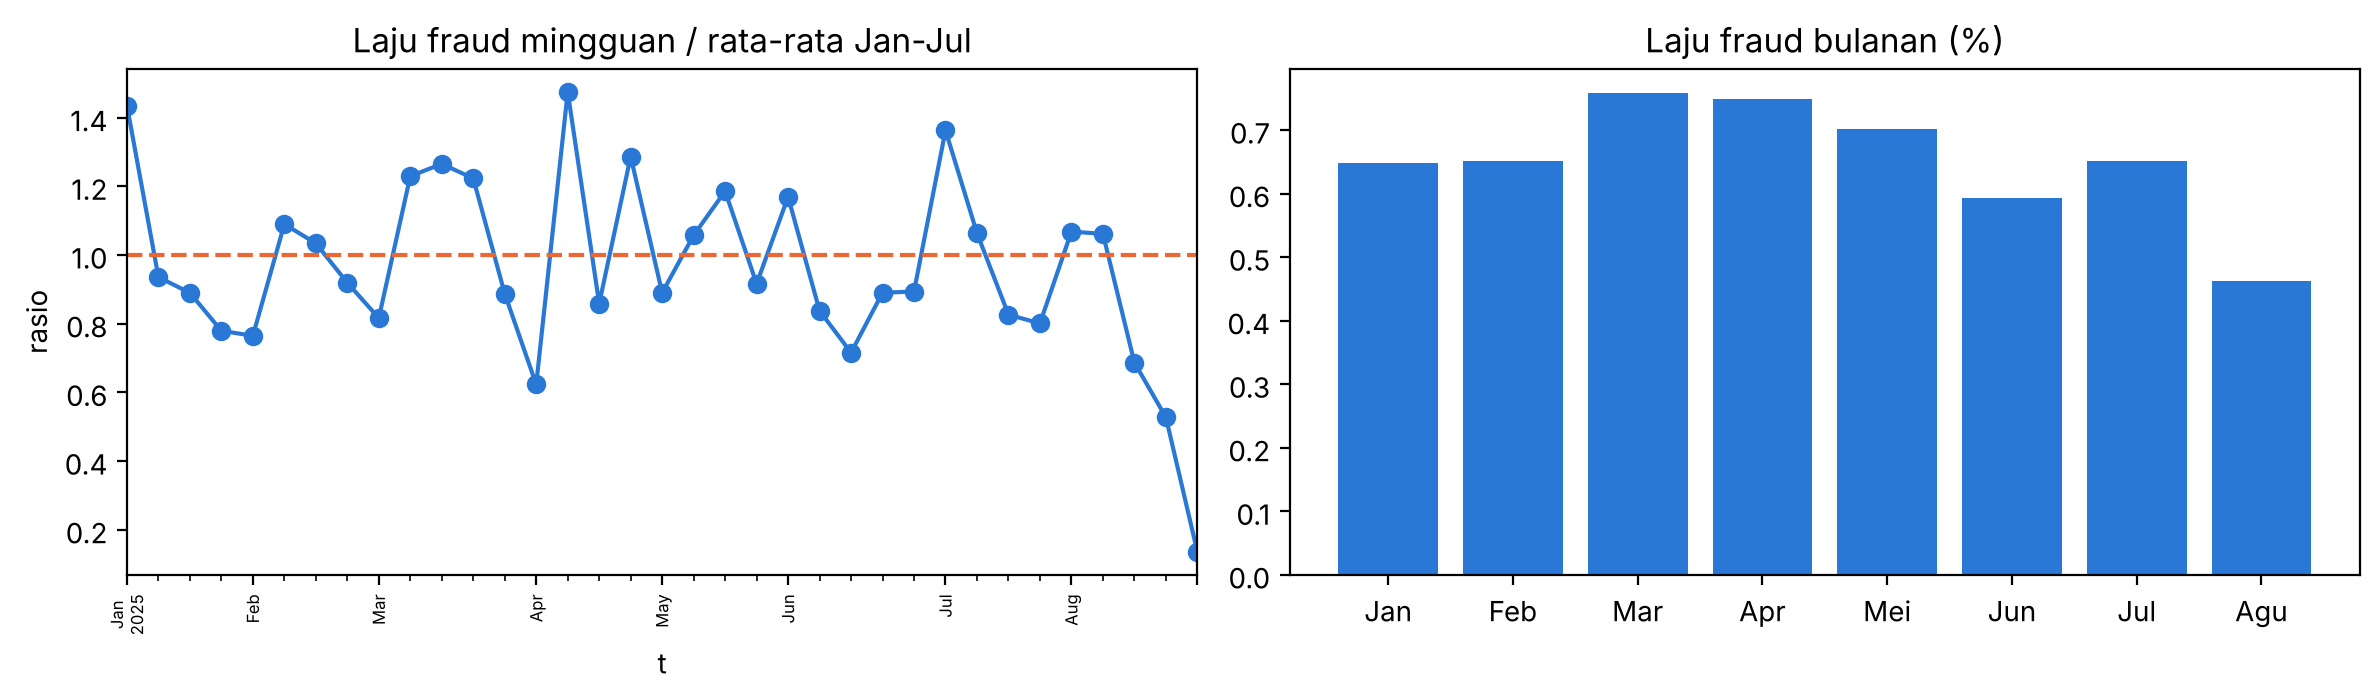

t
2025-07-14/2025-07-20    0.83
2025-07-21/2025-07-27    0.80
2025-07-28/2025-08-03    1.07
2025-08-04/2025-08-10    1.06
2025-08-11/2025-08-17    0.69
2025-08-18/2025-08-24    0.53
2025-08-25/2025-08-31    0.14
Freq: W-SUN


In [2]:
w=tr.groupby(tr.t.dt.to_period('W')).is_fraud.mean()
base=tr[tr.t<'2025-08-01'].is_fraud.mean()
fig,ax=plt.subplots(1,2,figsize=(12,3.6))
(w/base).plot(ax=ax[0],color='#2a78d6',marker='o'); ax[0].axhline(1,color='#eb6834',ls='--'); ax[0].set_title('Laju fraud mingguan / rata-rata Jan-Jul'); ax[0].set_ylabel('rasio'); ax[0].tick_params(axis='x',labelrotation=90,labelsize=6)
ax[1].bar(range(8),[ (tr[tr.t.dt.month==m].is_fraud.mean()*100) for m in range(1,9)],color='#2a78d6'); ax[1].set_xticks(range(8)); ax[1].set_xticklabels(['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu']); ax[1].set_title('Laju fraud bulanan (%)')
plt.tight_layout(); plt.show()
print((w/base).tail(7).round(2).to_string())

Laju fraud turun tajam sejak sekitar pertengahan Agustus (minggu terakhir hampir nol): label transaksi terbaru belum matang. Dari kurva ini, **jeda kematangan $L=21$ hari** dipakai: hanya transaksi dengan $t\le 10$ Agustus 2025 yang labelnya dianggap lengkap.

**(ii) `flag_review_manual`.** Fitur ini berarti "pernah ditinjau manual oleh tim risiko". Peninjauan terjadi setelah transaksi dicurigai/dilaporkan, jadi tidak tersedia saat transaksi diproses. Lihat hubungannya dengan label:

In [3]:
print(pd.crosstab(tr.flag_review_manual,tr.is_fraud,normalize='index').round(4).to_string())
print('proporsi ditinjau: train %.2f%% | test %.2f%%'%(100*tr.flag_review_manual.mean(),100*te.flag_review_manual.mean()))
print(tr.groupby(tr.t.dt.to_period('M')).flag_review_manual.mean().round(4).to_string())

is_fraud                 0       1
flag_review_manual                
0                   0.9987  0.0013
1                   0.6963  0.3037
proporsi ditinjau: train 1.71% | test 1.23%
t
2025-01    0.0168
2025-02    0.0176
2025-03    0.0178
2025-04    0.0189
2025-05    0.0164
2025-06    0.0169
2025-07    0.0167
2025-08    0.0161
Freq: M


Transaksi yang ditinjau memiliki fraud 30,4% versus 0,13% yang tidak. Pola ini khas **kebocoran** (akibat dari fraud, bukan penyebab yang dapat diketahui saat itu). Dampaknya diukur pada bagian 3 (ablasi). Fitur ini **tidak dipakai** pada model akhir.

**(iii) Fitur lain.** `v01–v50` anonim; semua fitur lain berupa profil/riwayat saat transaksi. Sebagian kolom (`menit_sejak_trx_terakhir`, `rasio_nominal_rata2`) kosong 22% — transaksi pertama pengguna; dibiarkan `NaN` (LightGBM menanganinya).

## 2. Fitur perilaku tanpa informasi masa depan (soal c)
Semua transaksi (train dan test) diurutkan menurut waktu; setiap fitur riwayat untuk transaksi ke-$i$ hanya memakai transaksi **sebelum** $i$: jumlah transaksi sebelumnya pengguna/merchant, umur sejak pertama terlihat, rata-rata nominal sebelumnya dan rasio nominal terhadapnya, pasangan pengguna–merchant, porsi QRIS merchant, jumlah pengguna baru merchant. Riwayat **berlabel** (jumlah fraud sebelumnya di pengguna/merchant) memakai jeda 21 hari: hanya label dari transaksi berumur ≥ 21 hari yang dihitung.

In [4]:
SEED=42; LAG=pd.Timedelta(days=21); LAB_MAX=pd.Timestamp('2025-08-10 23:59:59')
CATS=['kanal','kategori_merchant','tipe_perangkat','email_domain']
VCOLS=[f'v{i:02d}' for i in range(1,51)]
BASE_NUM=['nominal','jam','hari_libur','umur_akun_hari','level_kyc','umur_pengguna_tahun','umur_perangkat_hari','perangkat_baru','jumlah_akun_per_perangkat','ganti_password_7h','gagal_login_24j','jarak_lokasi_km','negara_ip_beda','kartu_tidak_hadir','menit_sejak_trx_terakhir','trx_1j','trx_24j','trx_7h','nominal_24j','rasio_nominal_rata2','saldo_sebelum','persen_saldo','umur_merchant_hari','refund_merchant_30h','volume_merchant_30h']
def lagged_counts(ent, t, y, lab_ok):
    """untuk tiap baris i: jumlah fraud & jumlah transaksi berlabel milik entitas yang sama dengan t_j <= t_i - LAG (dan t_j <= LAB_MAX)."""
    n=len(t); fr=np.zeros(n); nl=np.zeros(n)
    tv=t.values.astype('datetime64[s]').astype('int64'); lag=int(LAG.total_seconds())
    order=np.lexsort((tv,ent)); e=ent[order]; ts=tv[order]; yy=y[order]; ok=lab_ok[order]
    cut=np.flatnonzero(np.r_[True,e[1:]!=e[:-1],True])
    for a,b in zip(cut[:-1],cut[1:]):
        tt=ts[a:b]; okk=ok[a:b]; cf=np.r_[0,np.cumsum(yy[a:b]*okk)]; cn=np.r_[0,np.cumsum(okk)]
        idx=np.searchsorted(tt,tt-lag,side='right'); fr[order[a:b]]=cf[idx]; nl[order[a:b]]=cn[idx]
    return fr,nl
def build(tr,te):
    a=pd.concat([tr.assign(src='tr'),te.assign(src='te',is_fraud=np.nan)],ignore_index=True).sort_values('t',kind='stable').reset_index(drop=True)
    X=pd.DataFrame(index=a.index)
    for c in BASE_NUM: X[c]=a[c]
    X['log_nominal']=np.log1p(a.nominal); X['nominal_per_saldo']=a.nominal/(a.saldo_sebelum+1)
    X['jam_sin']=np.sin(2*np.pi*a.jam/24); X['jam_cos']=np.cos(2*np.pi*a.jam/24); X['dow']=a.t.dt.dayofweek
    for c in VCOLS: X[c]=a[c]
    # riwayat tanpa label (hanya masa lalu): urutan sudah menurut waktu
    for key,pre in (('id_pengguna','u'),('id_merchant','m')):
        g=a.groupby(key,sort=False); X[f'{pre}_n_prior']=g.cumcount()
        first=g.t.transform('min'); X[f'{pre}_hari_sejak_pertama']=(a.t-first).dt.total_seconds()/86400
        cs=g.nominal.cumsum()-a.nominal; X[f'{pre}_nominal_rata_prior']=np.where(X[f'{pre}_n_prior']>0,cs/X[f'{pre}_n_prior'].clip(lower=1),np.nan)
        X[f'nominal_rel_{pre}']=a.nominal/X[f'{pre}_nominal_rata_prior']
    X['um_n_prior']=a.groupby(['id_pengguna','id_merchant'],sort=False).cumcount()
    X['m_qris_share_prior']=np.where(X.m_n_prior>0,((a.kanal=='qris').astype(int).groupby(a.id_merchant,sort=False).cumsum()-(a.kanal=='qris').astype(int))/X.m_n_prior.clip(lower=1),np.nan)
    X['m_pengguna_baru_prior']=(a.groupby('id_merchant',sort=False).apply(lambda d:(~d.id_pengguna.duplicated()).cumsum()).reset_index(level=0,drop=True)-1).reindex(a.index)
    # riwayat berlabel dengan jeda kematangan 21 hari
    y=a.is_fraud.fillna(0).to_numpy(); lab_ok=((a.src=='tr')&(a.t<=LAB_MAX)).to_numpy().astype(float)
    for key,pre in (('id_pengguna','u'),('id_merchant','m')):
        ent=pd.factorize(a[key])[0]; fr,nl=lagged_counts(ent,a.t,y,lab_ok); X[f'{pre}_fraud_matang']=fr; X[f'{pre}_n_berlabel']=nl
        X[f'{pre}_fraud_rate_sm']=(fr+0.0065*20)/(nl+20)
    for c in CATS: X[c]=pd.Categorical(a[c])
    meta=a[['id_transaksi','t','nominal','is_fraud','src','kanal','kategori_merchant','flag_review_manual','id_merchant','id_pengguna']].copy()
    return X,meta

X,M=build(tr,te); y=M.is_fraud.to_numpy(); t=M.t; nom=M.nominal.to_numpy()
M['flag_review_manual']=M.flag_review_manual
print(X.shape)

(509751, 101)


## 3. Validasi berbasis waktu dengan label yang belum lengkap (soal b)

Skema: *expanding window* dengan **jeda (purge) 21 hari**. Untuk lipatan dengan jendela uji $[a,b)$, model hanya dilatih pada transaksi dengan $t<a-21$ hari, mencerminkan kondisi nyata (data latih berakhir 31 Agustus, label matang hanya sampai 10 Agustus, test mulai 1 September). Jendela uji juga hanya pada transaksi dengan label matang ($t\le 10$ Agustus). Tiga lipatan: uji Juni, Juli, dan 1–10 Agustus (lipatan terakhir memuat pola fraud baru). Early stopping memakai 21 hari terakhir jendela latih.

In [5]:
LAG=pd.Timedelta(days=21)
FOLDS=[('2025-06-01','2025-07-01'),('2025-07-01','2025-08-01'),('2025-08-01','2025-08-11')]
HIST=[c for c in X.columns if c.startswith(('u_','m_','um_','nominal_rel'))]; LABH=[c for c in HIST if 'fraud' in c or 'berlabel' in c]; NOLAB=[c for c in HIST if c not in LABH]
RAW=[c for c in X.columns if c not in HIST]
P=dict(objective='binary',learning_rate=0.05,num_leaves=31,min_data_in_leaf=100,feature_fraction=0.6,bagging_fraction=0.8,bagging_freq=1,lambda_l2=5,verbose=-1,seed=SEED,num_threads=4,max_bin=127)
def split(a,b):
    itr=np.where((t<pd.Timestamp(a)-LAG)&(M.src=='tr'))[0]; iva=np.where((t>=a)&(t<b)&(M.src=='tr'))[0]; return itr,iva
def fit_pred(cols,itr,iva,w=None,spw=None):
    p=dict(P); 
    if spw: p['scale_pos_weight']=spw
    tt=t.iloc[itr]; cut=tt.max()-pd.Timedelta(days=21); ia=itr[(tt<cut).to_numpy()]; ib=itr[(tt>=cut).to_numpy()]
    ds=lgb.Dataset(X.iloc[ia][cols],y[ia],weight=None if w is None else w[ia]); dv=lgb.Dataset(X.iloc[ib][cols],y[ib])
    m=lgb.train(dict(p,metric='average_precision'),ds,2000,valid_sets=[dv],callbacks=[lgb.early_stopping(100,verbose=False)])
    return m.predict(X.iloc[iva][cols],num_iteration=m.best_iteration),m.best_iteration
def cost(yv,nv,flag): return float((nv*yv*(1-flag)).sum()+25000*flag.sum())
def run(name,cols,down=None,nomw=False,spw=None):
    oof=[]
    for k,(a,b) in enumerate(FOLDS):
        itr,iva=split(a,b); w=None
        if down: keep=(y[itr]==1)|(np.random.default_rng(k).random(len(itr))<down); itr=itr[keep]
        if nomw: w=np.ones(len(X)); w[itr]=np.where(y[itr]==1,1+np.log1p(nom[itr]/1e5),1.0)
        p,it=fit_pred(cols,itr,iva,w=w,spw=spw); oof.append(pd.DataFrame({'idx':iva,'fold':k,'p':p,'y':y[iva],'nom':nom[iva]}))
    o=pd.concat(oof,ignore_index=True); pr=[ap(d.y,d.p) for _,d in o.groupby('fold')]
    print('%-46s PR-AUC per lipatan %s | rata-rata %.4f'%(name,np.round(pr,3),np.mean(pr)),flush=True); return o,pr

### Ablasi fitur: dampak kebocoran dan nilai fitur riwayat
Satuan PR-AUC (average precision), rata-rata tiga lipatan.

In [6]:
X['flag_review_manual']=M.flag_review_manual.to_numpy()
abl={}
abl['A. fitur mentah tanpa flag_review_manual']=run('A. mentah (tanpa flag_review_manual)',RAW)
abl['B. + flag_review_manual (BOCOR)']=run('B. + flag_review_manual (bocor)',RAW+['flag_review_manual'])
abl['C. mentah + riwayat tanpa label']=run('C. mentah + riwayat tanpa label',RAW+NOLAB)
abl['D. C + riwayat berlabel (jeda 21 hari)']=run('D. C + riwayat berlabel (jeda 21 hari)',RAW+HIST)
print(pd.DataFrame({k:[np.mean(v[1])]+v[1] for k,v in abl.items()},index=['rata2','Jun','Jul','Agu 1-10']).T.round(3).to_string())

A. mentah (tanpa flag_review_manual)           PR-AUC per lipatan [0.724 0.768 0.483] | rata-rata 0.6582


B. + flag_review_manual (bocor)                PR-AUC per lipatan [0.869 0.913 0.72 ] | rata-rata 0.8341


C. mentah + riwayat tanpa label                PR-AUC per lipatan [0.75  0.79  0.506] | rata-rata 0.6820


D. C + riwayat berlabel (jeda 21 hari)         PR-AUC per lipatan [0.754 0.787 0.491] | rata-rata 0.6773


                                          rata2    Jun    Jul  Agu 1-10
A. fitur mentah tanpa flag_review_manual  0.658  0.724  0.768     0.483
B. + flag_review_manual (BOCOR)           0.834  0.869  0.913     0.720
C. mentah + riwayat tanpa label           0.682  0.750  0.790     0.506
D. C + riwayat berlabel (jeda 21 hari)    0.677  0.754  0.787     0.491


Temuan: memakai `flag_review_manual` menaikkan PR-AUC validasi sangat besar (artifisial, karena fitur ini berasal dari proses setelah transaksi) — **dikeluarkan**. Fitur riwayat tanpa label menambah PR-AUC secara konsisten; riwayat berlabel tidak menambah apa pun (dan labelnya basi untuk transaksi test) sehingga **tidak dipakai**. Fitur terpilih: skenario **C**.

## 4. Ketidakseimbangan kelas (soal d)
Fraud hanya ±0,65% transaksi. Dibandingkan empat pendekatan pada fitur C: (1) tanpa penyesuaian, (2) pembobotan kelas `scale_pos_weight=20`, (3) *undersampling* negatif 10%, (4) pembobotan sampel positif menurut nominal. Pendekatan ke-5, **penyetelan ambang berbasis biaya**, diterapkan pada semuanya di bagian 6.

In [7]:
COLS=RAW+NOLAB
imb={'1. tanpa penyesuaian':abl['C. mentah + riwayat tanpa label'][0]}
imb['2. class weight (spw=20)']=run('2. class weight (spw=20)',COLS,spw=20)[0]
imb['3. undersampling negatif 10%']=run('3. undersampling negatif 10%',COLS,down=0.10)[0]
imb['4. bobot positif ~ nominal']=run('4. bobot positif ~ nominal',COLS,nomw=True)[0]

2. class weight (spw=20)                       PR-AUC per lipatan [0.754 0.78  0.509] | rata-rata 0.6811


3. undersampling negatif 10%                   PR-AUC per lipatan [0.73  0.762 0.509] | rata-rata 0.6668


4. bobot positif ~ nominal                     PR-AUC per lipatan [0.753 0.785 0.484] | rata-rata 0.6742


## 5. Pergeseran pola fraud (soal e)
Laju fraud per kanal dan bulan, lalu penelusuran lonjakan pada QRIS di Agustus.

In [8]:
piv=tr.pivot_table(index=tr.t.dt.to_period('M'),columns='kanal',values='is_fraud',aggfunc='mean')*100; print(piv.round(2).to_string())
q=tr[(tr.kanal=='qris')&(tr.is_fraud==1)].assign(periode=lambda d:np.where(d.t>='2025-08-01','Agustus','Jan-Jul'))
print(); print(q.groupby('periode').agg(n=('nominal','size'),nominal_median=('nominal','median'),umur_merchant_median=('umur_merchant_hari','median'),persen_saldo_median=('persen_saldo','median')).round(2).to_string())
print('\nkategori fraud QRIS Agustus:',q[q.periode=='Agustus'].kategori_merchant.value_counts(normalize=True).head(3).round(2).to_dict())
first=M.groupby('id_merchant').t.transform('min'); ringm=(first>='2025-08-01')
print('\nmerchant yang pertama kali muncul sejak 1 Agustus: %d merchant | baris train %d (fraud %.0f%%) | baris test %d'%(M[ringm].id_merchant.nunique(),((M.src=='tr')&ringm).sum(),100*M[(M.src=='tr')&ringm&(t<='2025-08-10 23:59:59')].is_fraud.mean(),((M.src=='te')&ringm).sum()))
rn=M[(M.src=='tr')&ringm&(t<='2025-08-10 23:59:59')]; print('di antara merchant baru itu yang QRIS & umur <60 hari: baris train (<=10 Agu)',len(rn),'laju fraud',round(rn.is_fraud.mean(),3))

kanal    aplikasi  kartu  qris    va   web
t                                         
2025-01      0.41   1.85  0.12  0.77  1.60
2025-02      0.34   1.70  0.15  1.00  1.78
2025-03      0.44   2.04  0.14  1.11  1.89
2025-04      0.51   1.78  0.12  1.10  1.87
2025-05      0.39   2.08  0.11  0.84  1.89
2025-06      0.31   1.47  0.12  0.96  1.77
2025-07      0.34   1.77  0.09  0.95  1.94
2025-08      0.13   0.90  0.79  0.49  0.78

          n  nominal_median  umur_merchant_median  persen_saldo_median
periode                                                               
Agustus  92       1487400.0                  19.0                 3.71
Jan-Jul  92        456450.0                 869.5                 0.89

kategori fraud QRIS Agustus: {'jasa_lainnya': 0.43, 'toko_online': 0.3, 'makanan_minuman': 0.05}



merchant yang pertama kali muncul sejak 1 Agustus: 281 merchant | baris train 503 (fraud 31%) | baris test 2152
di antara merchant baru itu yang QRIS & umur <60 hari: baris train (<=10 Agu) 115 laju fraud 0.313


**Temuan:** sejak 2 Agustus muncul **jaringan merchant baru** (umur <60 hari, hanya QRIS, nominal besar, `persen_saldo` > 1) dengan laju fraud sangat tinggi. Pola ini hampir tidak ada di data sebelum Agustus, dan lebih banyak muncul di test. Dua hal diuji: (a) lipatan 1–10 Agustus mengukur performa saat pola baru muncul, (b) strategi adaptasi: bobot lebih besar untuk data Agustus.

Uji adaptasi: latih pada seluruh data bermatang ($t\le10$ Agu) dengan bobot $w$ untuk transaksi 1–10 Agustus, lalu nilai pada transaksi jaringan baru **setelah** 10 Agustus (tidak dipakai latih). Fraud yang sudah terkonfirmasi di sana dapat dipercaya, non-fraud-nya sebagian besar adalah fraud yang belum terkonfirmasi.

In [9]:
CUT=pd.Timestamp('2025-08-10 23:59:59')
itr_f=np.where((t<=CUT)&(M.src=='tr'))[0]; late=np.where((t>CUT)&(M.src=='tr')&ringm.to_numpy())[0]
rows=[]
for wv in [1,5,15]:
    w=np.ones(len(X)); w[itr_f[(t.iloc[itr_f]>='2025-08-01').to_numpy()]]=wv
    m=lgb.train(P,lgb.Dataset(X.iloc[itr_f][COLS],y[itr_f],weight=w[itr_f]),350); p=m.predict(X.iloc[late][COLS]); yy=y[late]; nn=nom[late]; fl=p*nn>25000
    rows.append(dict(bobot_Agustus=wv,fraud_terkonfirmasi=int(yy.sum()),fraud_tertandai=int((fl&(yy==1)).sum()),skor_rata2_fraud=round(p[yy==1].mean(),3)))
# pembanding: latih dengan skema validasi (tanpa Agustus karena early stopping memakai 21 hari terakhir)
p0,_=fit_pred(COLS,itr_f,late); rows.insert(0,dict(bobot_Agustus='0 (Agu dipakai utk early stopping)',fraud_terkonfirmasi=int(y[late].sum()),fraud_tertandai=int(((p0*nom[late]>25000)&(y[late]==1)).sum()),skor_rata2_fraud=round(p0[y[late]==1].mean(),3)))
print(pd.DataFrame(rows).to_string(index=False))

                     bobot_Agustus  fraud_terkonfirmasi  fraud_tertandai  skor_rata2_fraud
0 (Agu dipakai utk early stopping)                   39               10             0.086
                                 1                   39               30             0.402
                                 5                   39               33             0.561
                                15                   39               34             0.589


Memasukkan data Agustus ke pelatihan sangat penting untuk menangkap pola baru; bobot 5 dipilih (sebagian besar fraud baru tertangkap tanpa membuat model terlalu fokus pada jaringan itu). Karena itu **model akhir dilatih tanpa early stopping pada data Agustus**, dengan jumlah iterasi tetap dari validasi.

## 6. Kalibrasi dan keputusan berbasis biaya (soal f)
Untuk transaksi dengan probabilitas terkalibrasi $\hat p_i$ dan nominal $a_i$, menandai transaksi menghemat $\hat p_i a_i$ (fraud yang tertahan) dengan ongkos Rp 25.000. Aturan optimal:
$$\text{tandai}_i=1 \iff \hat p_i\,a_i > 25000 .$$
Kalibrasi dibandingkan: mentah, Platt (regresi logistik pada logit, menjaga urutan sehingga PR-AUC tidak berubah), dan isotonik (monoton, tetapi menimbulkan nilai yang sama). Diuji *leave-one-fold-out*.

                    kalibrasi  biaya_juta_rp  Brier_x1e3  PR_AUC
                       mentah          132.2       3.276   0.682
                        Platt          108.0       3.191   0.682
                     isotonik          108.2       3.158   0.670
(pembanding) tandai tidak ada          916.1         NaN     NaN
    (pembanding) tandai semua         3003.7         NaN     NaN


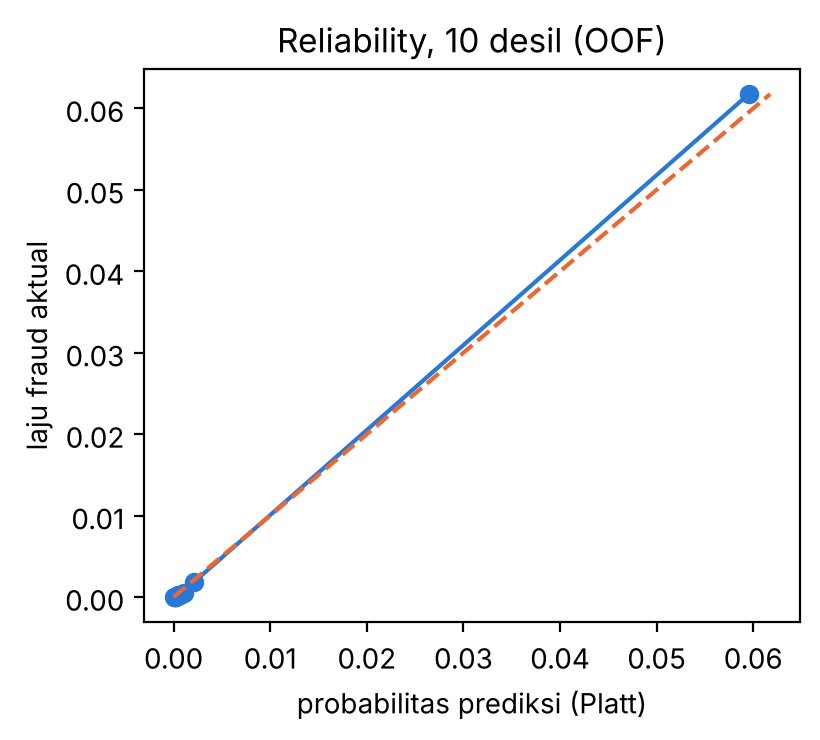

In [10]:
def logit(p): p=np.clip(p,1e-6,1-1e-6); return np.log(p/(1-p))
def calib(o,kind,k):
    r=o[o.fold!=k]; d=o[o.fold==k]
    if kind=='mentah': return d.p.values
    if kind=='Platt': lr=LogisticRegression(C=1e6).fit(logit(r.p.values).reshape(-1,1),r.y); return lr.predict_proba(logit(d.p.values).reshape(-1,1))[:,1]
    iso=IsotonicRegression(out_of_bounds='clip',y_min=0,y_max=1).fit(r.p,r.y); return iso.predict(d.p)
o=imb['1. tanpa penyesuaian']; res=[]
for kind in ['mentah','Platt','isotonik']:
    tot={'total':0}; br=[]; pa=[]
    for k in range(3):
        d=o[o.fold==k]; pc=calib(o,kind,k); fl=(pc*d.nom.values>25000).astype(int); tot['total']+=cost(d.y.values,d.nom.values,fl); br.append(np.mean((pc-d.y.values)**2)); pa.append(ap(d.y,pc))
    res.append(dict(kalibrasi=kind,biaya_juta_rp=round(tot['total']/1e6,1),Brier_x1e3=round(1e3*np.mean(br),3),PR_AUC=round(np.mean(pa),4)))
tak=sum(cost(d.y.values,d.nom.values,np.zeros(len(d))) for _,d in o.groupby('fold')); sem=sum(cost(d.y.values,d.nom.values,np.ones(len(d))) for _,d in o.groupby('fold'))
res.append(dict(kalibrasi='(pembanding) tandai tidak ada',biaya_juta_rp=round(tak/1e6,1))); res.append(dict(kalibrasi='(pembanding) tandai semua',biaya_juta_rp=round(sem/1e6,1)))
print(pd.DataFrame(res).to_string(index=False))
d=o.copy(); d['pc']=np.concatenate([calib(o,'Platt',k) for k in range(3)]); d['bin']=pd.qcut(d.pc.rank(method='first'),10,labels=False)
rel=d.groupby('bin').agg(prediksi=('pc','mean'),aktual=('y','mean')); fig,ax=plt.subplots(figsize=(4.2,3.8)); ax.plot(rel.prediksi,rel.aktual,'o-',color='#2a78d6'); mx=max(rel.max()); ax.plot([0,mx],[0,mx],'--',color='#eb6834'); ax.set_xlabel('probabilitas prediksi (Platt)'); ax.set_ylabel('laju fraud aktual'); ax.set_title('Reliability, 10 desil (OOF)'); plt.tight_layout(); plt.show()

Aturan biaya menurunkan biaya jauh di bawah dua pembanding. **Platt** dipilih: kalibrasi sebaik isotonik, tetapi menjaga urutan sehingga PR-AUC dari kolom `prob` tidak berkurang akibat nilai kembar.

### Perbandingan pendekatan imbalance (PR-AUC dan biaya dengan kalibrasi Platt dan aturan biaya)

In [11]:
tab=[]
for nm,oo in imb.items():
    pr=[];bi=0
    for k in range(3):
        d=oo[oo.fold==k]; pc=calib(oo,'Platt',k); pr.append(ap(d.y,pc)); bi+=cost(d.y.values,d.nom.values,(pc*d.nom.values>25000).astype(int))
    tab.append(dict(pendekatan=nm,PR_AUC=round(np.mean(pr),4),biaya_juta_rp=round(bi/1e6,1)))
print(pd.DataFrame(tab).to_string(index=False))

                  pendekatan  PR_AUC  biaya_juta_rp
        1. tanpa penyesuaian  0.6820          108.0
    2. class weight (spw=20)  0.6798          119.7
3. undersampling negatif 10%  0.6668          114.9
  4. bobot positif ~ nominal  0.6742          121.7


Perbedaan antarpendekatan kecil; pembobotan/undersampling tidak memberi keuntungan jelas terhadap model tanpa penyesuaian yang kemudian dikalibrasi dan diberi ambang berbasis biaya. Dipakai **tanpa penyesuaian + kalibrasi Platt + ambang biaya** (paling sederhana dan probabilitasnya langsung bermakna).

## 7. Analisis galat (soal g)

In [12]:
d=o.copy(); d['pc']=np.concatenate([calib(o,'Platt',k) for k in range(3)]); d['flag']=(d.pc*d.nom>25000).astype(int)
meta=M.iloc[d.idx.values][['kanal','kategori_merchant']].reset_index(drop=True); d=d.reset_index(drop=True).join(meta); d['baru']=ringm.iloc[o.idx.values].values
def tabel(col):
    g=d.groupby(col).apply(lambda x:pd.Series(dict(n=len(x),fraud=int(x.y.sum()),PR_AUC=ap(x.y,x.pc) if x.y.sum()>0 else np.nan,recall_tandai=(x.flag[x.y==1].mean() if x.y.sum()>0 else np.nan),presisi_tandai=(x.y[x.flag==1].mean() if x.flag.sum()>0 else np.nan),biaya_juta=cost(x.y.values,x.nom.values,x.flag.values)/1e6)))
    return g.round(3)
print(tabel('kanal').to_string()); print(); print(tabel('kategori_merchant').sort_values('fraud',ascending=False).head(10).to_string())
print('\nFraud yang lolos terbesar (OOF):'); print(d[(d.y==1)&(d.flag==0)].sort_values('nom',ascending=False)[['kanal','kategori_merchant','nom','pc']].head(8).round(4).to_string())

                n  fraud  PR_AUC  recall_tandai  presisi_tandai  biaya_juta
kanal                                                                      
aplikasi  53605.0  168.0   0.612          0.577           0.224      23.931
kartu     14819.0  236.0   0.808          0.708           0.522      18.179
qris      26522.0   69.0   0.154          0.406           0.160      43.738
va        17757.0  169.0   0.745          0.870           0.495      13.339
web        7443.0  135.0   0.863          0.733           0.604       8.790



                         n  fraud  PR_AUC  recall_tandai  presisi_tandai  biaya_juta
kategori_merchant                                                                   
voucher_game        5645.0  118.0   0.854          0.788           0.816       3.971
elektronik         12858.0  108.0   0.756          0.833           0.259      21.257
toko_online         9675.0   86.0   0.748          0.512           0.620       4.440
gadget              5014.0   86.0   0.712          0.884           0.317      12.789
pulsa_data         11299.0   78.0   0.797          0.474           0.822       2.286
top_up_ewallet      6233.0   74.0   0.923          0.892           0.680       5.070
fashion             8166.0   54.0   0.227          0.315           0.138      13.000
emas                1898.0   43.0   0.768          0.930           0.294       4.090
kecantikan          5224.0   33.0   0.209          0.212           0.119       6.749
makanan_minuman    17768.0   27.0   0.807          0.778         

## 8. Model akhir dan prediksi test

In [13]:
NIT=400
itr_f=np.where((t<=CUT)&(M.src=='tr'))[0]; ite=np.where(M.src=='te')[0]
w=np.ones(len(X)); w[itr_f[(t.iloc[itr_f]>='2025-08-01').to_numpy()]]=5.0
models=[lgb.train(dict(P,seed=SEED+s,bagging_seed=SEED+s,feature_fraction_seed=SEED+s),lgb.Dataset(X.iloc[itr_f][COLS],y[itr_f],weight=w[itr_f]),NIT) for s in range(3)]
p_raw=np.mean([m.predict(X.iloc[ite][COLS]) for m in models],axis=0)
oo=pd.concat([imb['1. tanpa penyesuaian']]); lr=LogisticRegression(C=1e6).fit(logit(oo.p.values).reshape(-1,1),oo.y)
prob=lr.predict_proba(logit(p_raw).reshape(-1,1))[:,1]
nt=nom[ite]; tandai=(prob*nt>25000).astype(int)
sub=pd.DataFrame({'id_transaksi':M.id_transaksi.iloc[ite].values,'prob':prob.round(6),'tandai':tandai})
sub=te[['id_transaksi']].merge(sub,on='id_transaksi',how='left')
sub.to_csv('prediksi_klasifikasi.csv',index=False)
chk=pd.read_csv('prediksi_klasifikasi.csv')
assert list(chk.columns)==['id_transaksi','prob','tandai'] and len(chk)==len(te) and chk.id_transaksi.is_unique and set(chk.id_transaksi)==set(te.id_transaksi)
assert chk.prob.between(0,1).all() and chk.tandai.isin([0,1]).all() and chk.notna().all().all()
print('prediksi_klasifikasi.csv OK',chk.shape,'| ditandai %d (%.2f%%) | prob rata-rata %.4f | perkiraan fraud test %.0f'%(chk.tandai.sum(),100*chk.tandai.mean(),chk.prob.mean(),chk.prob.sum()))
rt=ringm.iloc[ite].values; print('transaksi merchant baru di test: %d | ditandai %.0f%% | prob rata-rata %.3f'%(rt.sum(),100*tandai[rt].mean(),prob[rt].mean()))

prediksi_klasifikasi.csv OK (106674, 3) | ditandai 1674 (1.57%) | prob rata-rata 0.0079 | perkiraan fraud test 838
transaksi merchant baru di test: 2152 | ditandai 21% | prob rata-rata 0.110


### Kepentingan fitur (gain) dan SHAP (`pred_contrib`)

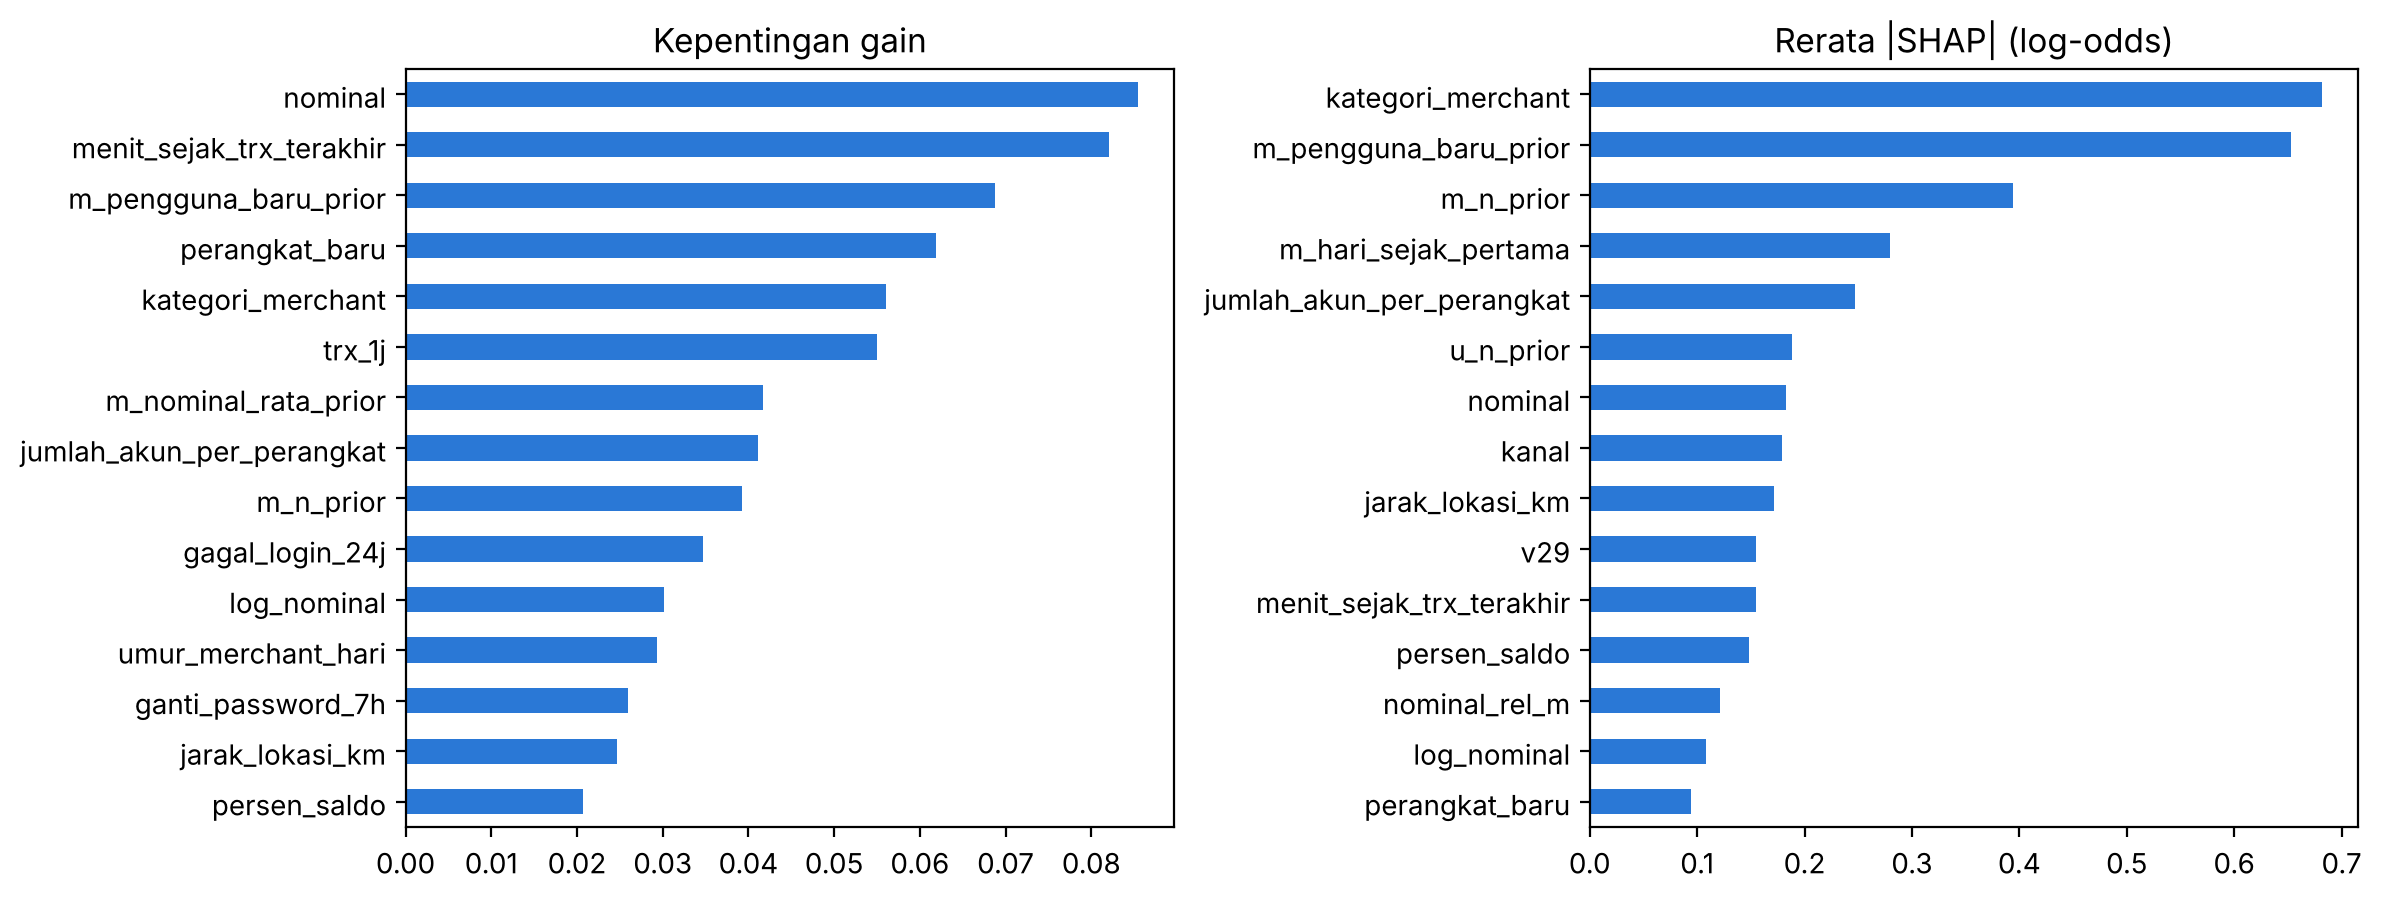

In [14]:
imp=pd.Series(models[0].feature_importance('gain'),index=COLS).sort_values(ascending=False); imp=imp/imp.sum()
smp=X.iloc[itr_f].sample(4000,random_state=SEED)[COLS]; sv=models[0].predict(smp,pred_contrib=True)[:,:-1]; sa=pd.Series(np.abs(sv).mean(0),index=COLS).sort_values(ascending=False)
fig,ax=plt.subplots(1,2,figsize=(12,4.6)); imp.head(15)[::-1].plot.barh(ax=ax[0],color='#2a78d6'); ax[0].set_title('Kepentingan gain'); sa.head(15)[::-1].plot.barh(ax=ax[1],color='#2a78d6'); ax[1].set_title('Rerata |SHAP| (log-odds)'); plt.tight_layout(); plt.show()

## 9. Ringkasan
- **Audit:** label belum matang pada ±3 minggu terakhir (jeda kematangan 21 hari); `flag_review_manual` bocor dan dikeluarkan (PR-AUC naik artifisial).
- **Validasi:** *expanding window* dengan jeda 21 hari; hanya label matang dipakai.
- **Fitur:** fitur mentah + riwayat pengguna/merchant tanpa informasi masa depan; riwayat berlabel tidak membantu.
- **Imbalance:** empat pendekatan setara; dipilih model tanpa penyesuaian + kalibrasi + ambang biaya.
- **Pergeseran:** jaringan merchant baru sejak Agustus (QRIS, nominal besar); data Agustus dibobot lebih besar pada model akhir.
- **Keputusan:** $\text{tandai}=1\iff\hat p\,a>25000$; jauh lebih murah daripada menandai semua atau tidak sama sekali.
- **Keterbatasan:** hanya ±10 hari data pola baru yang matang; kalibrasi dilakukan pada rezim lama sehingga probabilitas jaringan baru cenderung terlalu rendah (menandai tetap terjadi karena nominal besar).
- Keluaran: `prediksi_klasifikasi.csv`.